In [2]:
import os
import subprocess

prefix = subprocess.check_output(["brew", "--prefix", "cairo"], text=True).strip()
os.environ["DYLD_LIBRARY_PATH"] = f"{prefix}/lib"

In [3]:
import cairo

from thesis.render.marker import draw_crosshair, draw_marker

context = cairo.Context(cairo.ImageSurface(cairo.FORMAT_ARGB32, 64, 64))

context = draw_crosshair(context, 32, 32, 10, [230, 20, 20], 1)

context.get_target().write_to_png("marker.png")

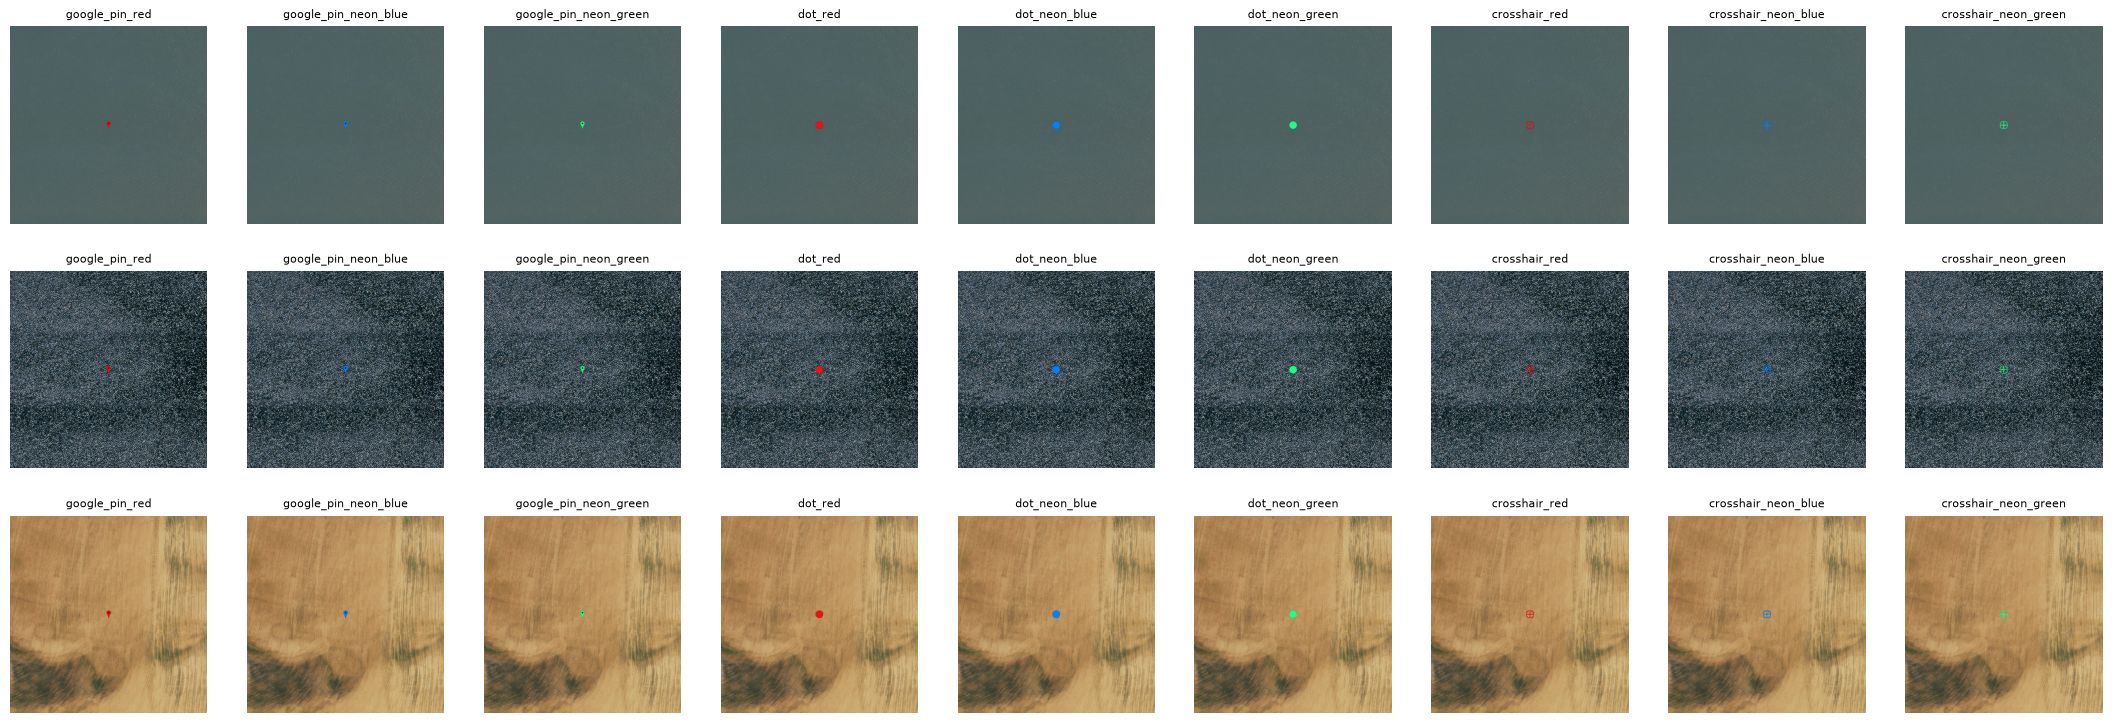

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml

from thesis.render.presets import load_presets

imagery_cfg = yaml.safe_load(Path("/Users/phillip/repositories/bachelor-thesis/configs/imagery.yaml").read_text())
render_cfg = yaml.safe_load(Path("/Users/phillip/repositories/bachelor-thesis/configs/render.yaml").read_text())
presets = load_presets(render_cfg)

cache_dir = Path(imagery_cfg["cache_dir"])
tile_paths = sorted(cache_dir.glob("*.npy"))[:3]

fig, axes = plt.subplots(len(tile_paths), len(presets), figsize=(3 * len(presets), 3 * len(tile_paths)))
for row, tile_path in enumerate(tile_paths):
    tile = np.load(tile_path)
    size = tile.shape[-1]
    for col, (name, cfg) in enumerate(presets.items()):
        out = draw_marker(tile, px=size // 2, py=size // 2, **cfg)
        ax = axes[row, col]
        ax.imshow(np.transpose(out, (1, 2, 0)))
        ax.set_title(name, fontsize=8)
        ax.axis("off")

fig.savefig("tests.png", dpi=150, bbox_inches="tight")